# Análise espectral do EEG: da FFT ao espectrograma

Este notebook mostra como um sinal de EEG é decomposto nas suas **frequências** e como essa decomposição dá origem às medidas e tendências de EEG quantitativo (qEEG): potência por bandas, razões entre bandas, frequência de corte espectral e espectrograma.

O notebook é **autónomo**: não pressupõe nenhuma sessão anterior. Os passos de preparação do sinal que interessam para a análise espectral (filtragem, referência, artefactos) são explicados quando surgem.

**Não são necessários conhecimentos de programação.**
- Cada bloco é executado selecionando-o e premindo **Shift + Enter** (ou o botão ▶). Os blocos devem ser executados **pela ordem apresentada**.
- Os blocos identificados apenas por um título (preparação e funções auxiliares) têm o código recolhido; o código pode ser consultado em **Show code**.
- Muitos blocos têm **controlos** (deslizantes, listas, caixas de texto) no Colab: altere o valor e execute novamente o bloco. Fora do Colab, altere o valor diretamente no código, na linha marcada com `#@param`.

### Como explorar
Ao longo do notebook surgem três tipos de notas:
- 🔧 **Experimente** — uma alteração concreta num controlo e o que observar;
- ❓ **Pergunta** — para pensar (ou discutir) antes de continuar; a resposta está escondida em **Resposta** (clique para abrir);
- ⚠️ **Atenção** — armadilhas frequentes na interpretação de qEEG.

Não há forma de "estragar" o notebook: em caso de dúvida, **Runtime → Run all** repõe tudo.

### Vocabulário mínimo
| Termo | Significado |
|---|---|
| **Elétrodo (canal)** | ponto do escalpe onde se mede o sinal. Nomes do sistema 10-20: Fp = frontopolar, F = frontal, C = central, T = temporal, P = parietal, O = occipital; números ímpares à esquerda, pares à direita, "z" na linha média |
| **Frequência de amostragem** | número de medições por segundo (Hz). Só se podem analisar frequências até **metade** deste valor |
| **Referência** | o EEG mede sempre uma **diferença** de potencial entre dois pontos. Na **referência média**, a cada elétrodo subtrai-se a média de todos |
| **Filtro** | remove as frequências fora de um intervalo (ex.: 1-40 Hz) |
| **Artefacto** | sinal registado que **não tem origem no cérebro**: pestanejos, movimentos oculares, músculo, movimento, mau contacto de um elétrodo, rede elétrica |
| **Época** | segmento de sinal de duração fixa (ex.: 2 s) sobre o qual se calcula um espectro |
| **Bandas** | delta (1-4 Hz), teta (4-8 Hz), alfa (8-13 Hz), beta (13-30 Hz) |

### Conteúdo
1. **O EEG como soma de oscilações**: sinais sintéticos e o seu espectro
2. **Da amplitude à potência**: µV, µV² e decibéis
3. **Resolução em frequência**: a importância da duração da janela
4. **O método de Welch**: espectros mais estáveis
5. **Olhos abertos e olhos fechados**: o ritmo alfa num registo real — preparação do sinal, filtragem e artefactos
6. **Medidas espectrais**: potência absoluta e relativa, razões, SEF95 e pico alfa
7. **Mapas topográficos**: onde está a potência no escalpe
8. **O espectrograma**: a FFT ao longo do tempo
9. **Tendências de qEEG**: do espectrograma às curvas utilizadas na monitorização
10. **Registos diferentes**: as mesmas medidas em EEG diferentes (registos de exemplo ou ficheiros próprios)

In [82]:
#@title Preparação: instalação e carregamento das bibliotecas
# No Colab, a biblioteca MNE-Python é instalada através do gestor de pacotes pip; o relatório
# detalhado da instalação só é apresentado se ocorrer um erro.
import subprocess, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("A instalar o MNE...")
    result = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "mne"],
                            capture_output=True, text=True)
    print("Instalação concluída." if result.returncode == 0 else result.stderr)

# Bibliotecas utilizadas:
#   numpy      - cálculo numérico com vetores e matrizes
#   scipy      - processamento de sinal (FFT, método de Welch, espectrograma)
#   matplotlib - produção de gráficos
#   mne        - leitura, processamento e visualização de sinais de EEG
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
import mne
from mne.datasets import eegbci

mne.set_log_level("ERROR")                 # o MNE apresenta apenas mensagens de erro
plt.rcParams["figure.dpi"] = 100           # resolução das figuras

# Pasta onde são guardados os registos descarregados: no Colab, na sessão; localmente, na pasta
# data/ do projeto (e não dentro de notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

# Bandas de frequência clássicas (Hz). Os limites variam ligeiramente entre autores e
# programas; estes seguem aproximadamente o glossário da IFCN (Kane et al., 2017).
BANDS = {"delta": (1, 4), "teta": (4, 8), "alfa": (8, 13), "beta": (13, 30)}
BAND_COLORS = {"delta": "tab:purple", "teta": "tab:blue", "alfa": "tab:green", "beta": "tab:orange"}


def download_example(file_name):
    # Descarrega um registo da base de dados PhysioNet (apenas na primeira execução) e devolve o
    # caminho do ficheiro. O nome indica o participante e a sessão: "S001R01.edf" = participante 1, sessão 1.
    subject, run = int(file_name[1:4]), int(file_name[5:7])
    return eegbci.load_data(subject, [run], path=RAW_DIR, update_path=False)[0]

In [83]:
#@title Funções auxiliares (sinais sintéticos)
# Funções utilizadas nas secções 1 a 4. Não alteram os dados.

FS = 256   # frequência de amostragem dos sinais sintéticos (amostras por segundo)


def make_signal(duration=4.0, components=(), noise=2.0, seed=0):
    # Soma de oscilações sinusoidais: components = [(frequência em Hz, amplitude em µV), ...],
    # mais ruído aleatório com o desvio-padrão indicado (µV)
    t = np.arange(0, duration, 1 / FS)
    x = np.random.default_rng(seed).normal(0, noise, t.size)
    for freq, amp in components:
        x += amp * np.sin(2 * np.pi * freq * t)
    return t, x


def amplitude_spectrum(x, fs=FS):
    # FFT de um segmento: amplitude (µV) de cada frequência
    n = x.size
    freqs = np.fft.rfftfreq(n, 1 / fs)
    amp = 2 * np.abs(np.fft.rfft(x)) / n
    return freqs, amp


def plot_signal_and_spectrum(t, x, title, fmax=40, components=()):
    # Sinal no tempo (esquerda) e respetivo espectro de amplitude (direita)
    freqs, amp = amplitude_spectrum(x)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw=dict(width_ratios=[1.6, 1]))
    ax1.plot(t, x, color="black", lw=0.7)
    ax1.set_xlim(0, min(2, t[-1]))
    ax1.set_xlabel("Tempo (segundos)")
    ax1.set_ylabel("Amplitude (µV)")
    ax1.set_title("Domínio do tempo (primeiros 2 s)", loc="left")
    ax2.plot(freqs, amp, color="tab:red", lw=1.2)
    for freq, a in components:
        if a > 0:
            ax2.annotate(f"{freq:g} Hz", (freq, a), textcoords="offset points", xytext=(4, 4), fontsize=9)
    ax2.set_xlim(0, fmax)
    ax2.set_xlabel("Frequência (Hz)")
    ax2.set_ylabel("Amplitude (µV)")
    ax2.set_title("Domínio da frequência (FFT)", loc="left")
    for ax in (ax1, ax2):
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    plt.show()


def plot_resolution(x, windows, title, fmin=6, fmax=14):
    # Espectro do mesmo sinal calculado com janelas de diferentes durações
    fig, axes = plt.subplots(1, len(windows), figsize=(13, 3), sharey=True)
    for ax, w in zip(axes, windows):
        seg = x[: int(w * FS)]
        freqs, amp = amplitude_spectrum(seg)
        ax.plot(freqs, amp, color="tab:red", marker="o", ms=3, lw=1)
        ax.set_xlim(fmin, fmax)
        ax.set_title(f"Janela de {w:g} s  →  resolução {1 / w:g} Hz", loc="left")
        ax.set_xlabel("Frequência (Hz)")
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel("Amplitude (µV)")
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    plt.show()


def plot_welch_vs_single(x, title, window=2.0):
    # Periodograma de um único segmento vs. média de vários segmentos (Welch)
    seg = x[: int(window * FS)]
    f1, p1 = signal.periodogram(seg, FS, window="hann")
    f2, p2 = signal.welch(x, FS, nperseg=int(window * FS), noverlap=int(window * FS) // 2)
    fig, ax = plt.subplots(figsize=(10, 3.3))
    ax.semilogy(f1, p1, color="tab:gray", lw=1, label=f"um único segmento de {window:g} s")
    ax.semilogy(f2, p2, color="tab:red", lw=2, label=f"Welch: média de segmentos de {window:g} s (50% sobreposição)")
    ax.set_xlim(0, 40)
    ax.set_xlabel("Frequência (Hz)")
    ax.set_ylabel("Potência (µV²/Hz, escala log.)")
    ax.set_title(title, loc="left", fontweight="bold")
    ax.legend(loc="upper right")
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()

## 1. O EEG como soma de oscilações

O traçado de EEG que se observa no ecrã está no **domínio do tempo**: no eixo horizontal o tempo, no vertical a amplitude (µV).

O matemático Joseph Fourier mostrou que **qualquer sinal pode ser descrito como uma soma de oscilações sinusoidais** de diferentes frequências e amplitudes. A **Transformada de Fourier** — calculada no computador através do algoritmo **FFT** (*Fast Fourier Transform*) — faz essa decomposição: indica **quanto de cada frequência** está presente no sinal. Passa-se assim para o **domínio da frequência**.

Para começar, constrói-se um sinal artificial com três ritmos conhecidos: **delta (2 Hz)**, **alfa (10 Hz)** e **beta (20 Hz)**, mais algum ruído.

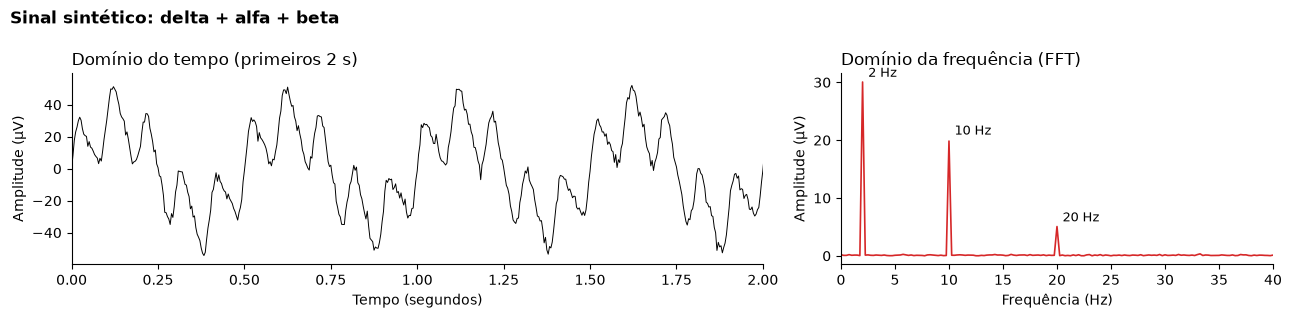

In [95]:
#@markdown Altere as amplitudes (µV) de cada ritmo e execute novamente o bloco.
delta_uV = 30  #@param {type:"slider", min:0, max:60, step:5}
alfa_uV = 20   #@param {type:"slider", min:0, max:60, step:5}
beta_uV = 5    #@param {type:"slider", min:0, max:60, step:5}

ritmos = [(2, delta_uV), (10, alfa_uV), (20, beta_uV)]   # (frequência em Hz, amplitude em µV)
t, x = make_signal(duration=4, components=ritmos)

plot_signal_and_spectrum(t, x, "Sinal sintético: delta + alfa + beta", components=ritmos)

No **domínio do tempo** (esquerda) os três ritmos estão misturados e é difícil estimar a contribuição de cada um. No **domínio da frequência** (direita) cada ritmo surge como um **pico isolado**, na sua frequência, com altura proporcional à sua amplitude.

🔧 **Experimente:** coloque `alfa_uV = 0`. O pico dos 10 Hz desaparece do espectro, mas no traçado a diferença é muito menos evidente.

> ❓ **Pergunta:** um pico de grande amplitude a 50 Hz num espectro de EEG corresponde, mais provavelmente, a que fenómeno?
>
> <details><summary>Resposta</summary>
>
> À **interferência da rede elétrica** (50 Hz na Europa, 60 Hz nas Américas): um artefacto, não atividade cerebral. Aparece num registo real na secção 5.
>
> </details>

O mesmo princípio explica um facto útil na prática: **formas de onda pontiagudas** (pontas, ondas agudas, artefacto muscular) contêm muitas frequências altas, enquanto **ondas suaves e arredondadas** concentram a energia em poucas frequências baixas.

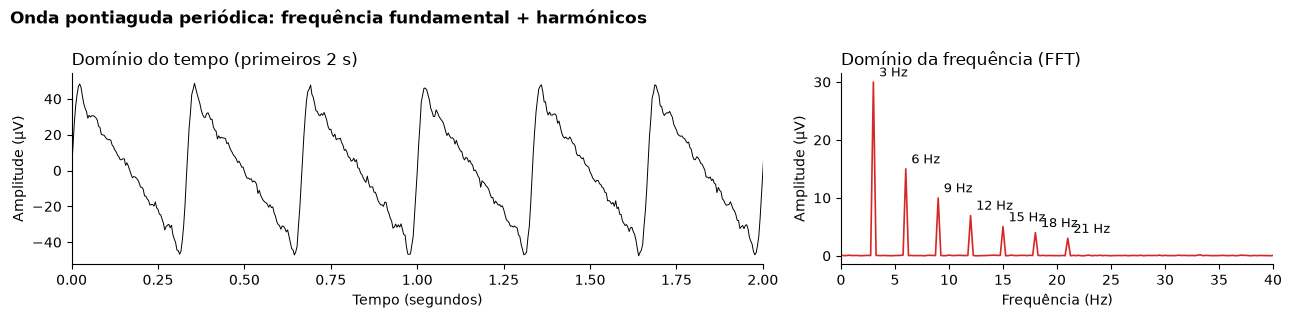

In [96]:
# Uma onda "pontiaguda": oscilação de 3 Hz com harmónicos (múltiplos de 3 Hz)
harmonicos = [(3, 30), (6, 15), (9, 10), (12, 7), (15, 5), (18, 4), (21, 3)]
t, x = make_signal(duration=4, components=harmonicos, noise=1)

plot_signal_and_spectrum(t, x, "Onda pontiaguda periódica: frequência fundamental + harmónicos",
                         components=harmonicos)

Uma descarga periódica a 3 Hz não produz apenas um pico a 3 Hz, mas uma **série de picos nos seus múltiplos** (6, 9, 12 Hz...), designados **harmónicos**. No espectrograma, este padrão aparece como várias **riscas horizontais paralelas** — um aspeto frequente em descargas periódicas.

## 2. Da amplitude à potência

Na prática, os programas de qEEG não apresentam a amplitude, mas a **potência**, que corresponde aproximadamente à **amplitude ao quadrado** (unidades: **µV²**, ou µV²/Hz quando normalizada pela largura de banda).

| Grandeza | Unidade | Observação |
|---|---|---|
| Amplitude | µV | a que se mede no traçado |
| Potência | µV² (ou µV²/Hz) | amplitude ao quadrado: duplicar a amplitude **quadruplica** a potência |
| Potência em decibéis | dB = 10·log₁₀(potência) | escala logarítmica, utilizada nos espectrogramas |

A escala **logarítmica (dB)** é necessária porque a potência do EEG varia muito com a frequência: as frequências lentas têm potência **dezenas a centenas de vezes** superior às rápidas. Numa escala linear, a atividade beta seria praticamente invisível. É por isso que as escalas de cor dos espectrogramas estão, habitualmente, em dB.

## 3. Resolução em frequência: a importância da duração da janela

A FFT é calculada sobre um **segmento** (janela, ou época) de sinal com uma determinada duração **T**. A distância entre as frequências que a FFT consegue distinguir — a **resolução em frequência** — é:

$$\Delta f = \frac{1}{T}$$

| Duração da janela | Resolução |
|---|---|
| 0,5 s | 2 Hz |
| 1 s | 1 Hz |
| 2 s | 0,5 Hz |
| 4 s | 0,25 Hz |

Exemplo: um sinal com **dois ritmos alfa muito próximos**, a 9,5 Hz e 10,5 Hz (como pode acontecer com um ritmo dominante posterior assimétrico):

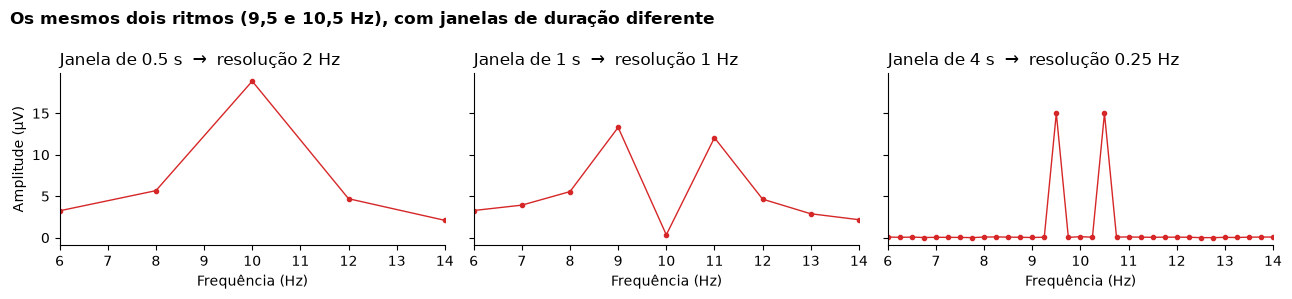

In [86]:
t, x = make_signal(duration=8, components=[(9.5, 15), (10.5, 15)], noise=1)

plot_resolution(x, windows=[0.5, 1, 4], title="Os mesmos dois ritmos (9,5 e 10,5 Hz), com janelas de duração diferente")

- Com **0,5 s** de janela (resolução de 2 Hz), os dois ritmos fundem-se num único pico largo.
- Com **1 s**, surgem dois picos, mas **nas frequências erradas** (9 e 11 Hz): a FFT só calcula valores em múltiplos de 1 Hz e os ritmos reais ficam "entre" esses pontos.
- Com **4 s**, os dois picos são claramente distintos.

⚠️ **Contrapartida:** janelas mais longas dão melhor resolução em frequência, mas **pior resolução temporal** — um evento breve (por exemplo, uma crise de 5 segundos) fica "diluído" numa janela longa. Esta escolha é feita, por vezes sem o utilizador saber, em todos os programas de qEEG. Para a monitorização em cuidados intensivos são habituais janelas de **2 a 4 segundos** (Ng et al., 2022).

> ❓ **Pergunta:** com épocas de 2 segundos, qual é a resolução em frequência? 
>
> <details><summary>Resposta</summary>
>
> 1/2 = **0,5 Hz**.
>
> </details>

## 4. O método de Welch

O espectro de **um único segmento** de EEG é muito irregular: o EEG é um sinal aleatório e cada segmento dá um resultado ligeiramente diferente. O **método de Welch** resolve este problema:

1. divide o registo em **segmentos curtos**, com sobreposição (habitualmente 50%);
2. aplica a cada segmento uma **janela** que suaviza as extremidades (janela de Hann), para evitar descontinuidades artificiais;
3. calcula a FFT de cada segmento;
4. faz a **média** dos espectros.

É o método utilizado por omissão no MNE-Python e, sob diferentes formas, na maioria dos programas de qEEG.

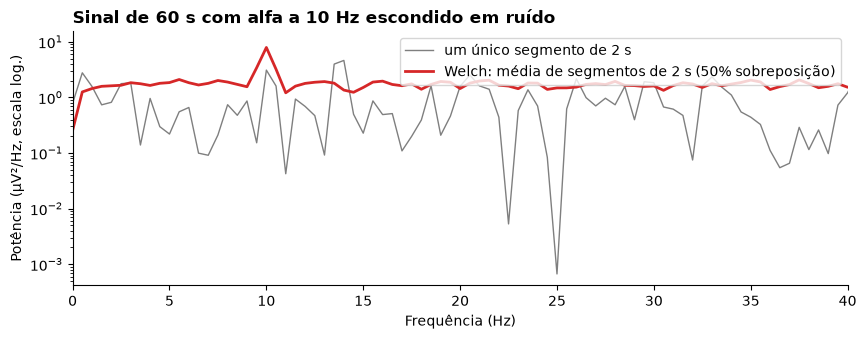

In [68]:
t, x = make_signal(duration=60, components=[(10, 3)], noise=15, seed=1)

plot_welch_vs_single(x, "Sinal de 60 s com alfa a 10 Hz escondido em ruído", window=2.0)

O espectro de um único segmento (cinzento) é muito irregular e o pico alfa confunde-se com as flutuações do ruído. A média de Welch (vermelho) é estável e o pico dos 10 Hz torna-se evidente. Quanto mais segmentos se incluem na média, mais estável é a estimativa — mas é necessário um registo mais longo.

## 5. Olhos abertos e olhos fechados: o ritmo alfa num registo real

A base de dados pública [PhysioNet EEG Motor Movement/Imagery](https://physionet.org/content/eegmmidb/1.0.0/) (109 participantes, gravada nos EUA) inclui, para cada participante, **1 minuto em repouso de olhos abertos** (sessão R01) e **1 minuto de olhos fechados** (sessão R02), com 64 elétrodos e 160 Hz de frequência de amostragem. Os ficheiros são descarregados automaticamente.

O aumento do ritmo alfa posterior ao fechar os olhos (**reatividade do alfa**, descrita por Hans Berger em 1929) é um dos fenómenos mais robustos do EEG e um bom teste para os métodos espectrais.

### Preparação do sinal

Antes de calcular espectros, cada registo passa por três passos:

1. **Posição dos elétrodos:** cada elétrodo é associado à sua posição no escalpe (necessário para os mapas da secção 7).
2. **Filtro passa-banda 1-40 Hz:** remove as **derivas lentas** abaixo de 1 Hz (suor, movimento dos cabos, respiração) e as frequências acima de 40 Hz, onde predominam a **interferência da rede elétrica** e o **artefacto muscular**. A atividade cerebral que se pretende medir (delta a beta) fica intacta.
3. **Referência média:** a cada elétrodo subtrai-se a média de todos, para que o sinal não dependa de um elétrodo de referência em particular.

Guarda-se também uma cópia **sem filtro**, para ver o efeito do passo 2.

In [87]:
#@markdown Participante da base de dados (1 a 109). Ao mudar, os dois registos são descarregados e todas as secções seguintes passam a usá-lo.
PARTICIPANTE = 1  #@param {type:"slider", min:1, max:109, step:1}

def load_run(file_name, filtrar=True):
    raw = mne.io.read_raw_edf(download_example(file_name), preload=True)
    eegbci.standardize(raw)              # uniformizar os nomes dos elétrodos (ex.: "Fp1." -> "Fp1")
    raw.set_montage("standard_1005")     # associar cada elétrodo à sua posição no escalpe
    raw.crop(tmax=60.0)                  # o último segundo dos ficheiros não contém sinal (zeros)
    if filtrar:
        raw.filter(l_freq=1.0, h_freq=40.0)  # filtro passa-banda 1-40 Hz
    raw.set_eeg_reference("average")     # referência média
    return raw

olhos_abertos = load_run(f"S{PARTICIPANTE:03d}R01.edf")
olhos_fechados = load_run(f"S{PARTICIPANTE:03d}R02.edf")
olhos_abertos_sem_filtro = load_run(f"S{PARTICIPANTE:03d}R01.edf", filtrar=False)

print(f"Participante {PARTICIPANTE}")
print(f"Olhos abertos : {olhos_abertos.times[-1]:.0f} s, {len(olhos_abertos.ch_names)} elétrodos")
print(f"Olhos fechados: {olhos_fechados.times[-1]:.0f} s, {len(olhos_fechados.ch_names)} elétrodos")
print(f"Frequência de amostragem: {olhos_abertos.info['sfreq']:.0f} Hz "
      f"(frequência máxima analisável: {olhos_abertos.info['sfreq'] / 2:.0f} Hz)")

Participante 1
Olhos abertos : 60 s, 64 elétrodos
Olhos fechados: 60 s, 64 elétrodos
Frequência de amostragem: 160 Hz (frequência máxima analisável: 80 Hz)


In [88]:
#@title Funções auxiliares (registo real)
# Funções utilizadas nas secções 5 a 9. Não alteram os dados.

# Grupos de elétrodos por região do escalpe (escolhidos nos controlos das secções 5 e 6)
REGIOES = {
    "posterior": ["O1", "Oz", "O2", "PO7", "PO8"],   # occipitais / parieto-occipitais
    "frontal": ["Fp1", "Fp2", "F3", "Fz", "F4"],
    "central": ["C3", "Cz", "C4"],
    "temporal": ["T7", "T8", "TP7", "TP8"],
}
POSTERIOR = REGIOES["posterior"]


def channel_list(text):
    # "Fp1, Fp2 ,O1" -> ["Fp1", "Fp2", "O1"]
    return [ch.strip() for ch in text.split(",") if ch.strip()]


def plot_traces_open_closed(open_rec, closed_rec, channels, start=0.0, duration=10.0, spacing=150):
    # Traçado dos mesmos elétrodos nas duas condições, lado a lado e com a mesma escala vertical
    fig, axes = plt.subplots(1, 2, figsize=(13, 0.55 * len(channels) + 1.6), sharey=True)
    for ax, rec, title in zip(axes, (open_rec, closed_rec), ("olhos abertos", "olhos fechados")):
        data, times = rec.get_data(picks=channels, tmin=start, tmax=start + duration, return_times=True)
        for i, trace in enumerate(data * 1e6):
            ax.plot(times, trace - trace.mean() - i * spacing, color="black", lw=0.6)
        ax.set_title(title, loc="left", fontweight="bold")
        ax.set_xlim(times[0], times[-1])
        ax.set_xlabel("Tempo (segundos)")
        ax.spines[["top", "right", "left"]].set_visible(False)
    axes[0].set_yticks(-np.arange(len(channels)) * spacing, channels)
    axes[1].plot([times[-1]] * 2, [spacing * 0.3, spacing * 0.3 + 100], color="tab:red", lw=3, clip_on=False)
    axes[1].text(times[-1], spacing * 0.3 + 50, "  100 µV", color="tab:red", va="center")
    fig.tight_layout()
    plt.show()


def plot_filter_effect(unfiltered, filtered, picks="eeg", window=2.0):
    # Espectro antes e depois do filtro 1-40 Hz, até à frequência máxima analisável (metade da amostragem)
    fmax = unfiltered.info["sfreq"] / 2
    fig, ax = plt.subplots(figsize=(11, 3.6))
    ax.axvspan(1, 40, color="tab:green", alpha=0.08)
    ax.text(20.5, 1.0, "banda mantida pelo filtro (1-40 Hz)", transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", color="tab:green", fontsize=10)
    for rec, color, label in [(unfiltered, "tab:red", "sem filtro"), (filtered, "black", "com filtro 1-40 Hz")]:
        n = int(window * rec.info["sfreq"])
        sp = rec.compute_psd(method="welch", fmin=0, fmax=fmax, picks=picks, n_fft=n, n_overlap=n // 2)
        ax.semilogy(sp.freqs, sp.get_data().mean(axis=0) * 1e12, color=color, lw=1.5, label=label)
    ax.set_xlim(0, fmax)
    ax.set_xlabel("Frequência (Hz)")
    ax.set_ylabel("Potência (µV²/Hz, escala log.)")
    ax.set_title("Efeito do filtro no espectro (média de todos os elétrodos)", loc="left", fontweight="bold", pad=18)
    ax.legend(loc="upper right")
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()


def psd(recording, picks=POSTERIOR, window=2.0):
    # Densidade espectral de potência pelo método de Welch (janelas de `window` s, 50% sobreposição),
    # média dos elétrodos indicados; devolve frequências (Hz) e potência (µV²/Hz)
    n = int(window * recording.info["sfreq"])
    sp = recording.compute_psd(method="welch", fmin=1, fmax=40, picks=picks,
                               n_fft=n, n_per_seg=n, n_overlap=n // 2)
    return sp.freqs, sp.get_data().mean(axis=0) * 1e12   # V²/Hz -> µV²/Hz


def plot_open_closed(open_rec, closed_rec, picks=POSTERIOR, log=True):
    # Espectros sobrepostos, com as bandas clássicas assinaladas
    fig, ax = plt.subplots(figsize=(11, 3.8))
    for name, (lo, hi) in BANDS.items():
        ax.axvspan(lo, hi, color=BAND_COLORS[name], alpha=0.08)
        ax.text((lo + hi) / 2, 1.0, name, transform=ax.get_xaxis_transform(), ha="center",
                va="bottom", color=BAND_COLORS[name], fontsize=10)
    for rec, color, label in [(open_rec, "tab:gray", "olhos abertos"), (closed_rec, "black", "olhos fechados")]:
        f, p = psd(rec, picks)
        (ax.semilogy if log else ax.plot)(f, p, color=color, lw=2, label=label)
    ax.set_xlim(1, 40)
    ax.set_xlabel("Frequência (Hz)")
    ax.set_ylabel("Potência (µV²/Hz)" + (", escala log." if log else ""))
    ax.set_title(f"Densidade espectral de potência ({', '.join(picks)})", loc="left", fontweight="bold", pad=18)
    ax.legend(loc="upper right")
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()


def band_measures(recording, picks=POSTERIOR):
    # Medidas espectrais clássicas a partir do espectro de Welch
    f, p = psd(recording, picks)
    df = f[1] - f[0]
    total = p[(f >= 1) & (f < 30)].sum() * df
    out = {}
    for name, (lo, hi) in BANDS.items():
        out[f"{name}_abs"] = p[(f >= lo) & (f < hi)].sum() * df     # potência absoluta (µV²)
        out[f"{name}_rel"] = out[f"{name}_abs"] / total              # potência relativa (0-1)
    out["ADR"] = out["alfa_abs"] / out["delta_abs"]                  # razão alfa/delta
    cumulative = np.cumsum(p[(f >= 1) & (f < 30)]) / p[(f >= 1) & (f < 30)].sum()
    out["SEF95"] = f[(f >= 1) & (f < 30)][np.searchsorted(cumulative, 0.95)]   # frequência de corte espectral
    alpha = (f >= 7) & (f <= 14)
    out["pico_alfa"] = f[alpha][np.argmax(p[alpha])]                  # frequência do pico alfa
    return out


def print_measures(open_rec, closed_rec, picks=POSTERIOR):
    a, c = band_measures(open_rec, picks), band_measures(closed_rec, picks)
    print(f"Elétrodos: {', '.join(picks)}\n")
    print(f"{'Medida':<34}{'Olhos abertos':>15}{'Olhos fechados':>16}")
    print("-" * 65)
    for name in BANDS:
        print(f"{'Potência absoluta ' + name + ' (µV²)':<34}{a[name + '_abs']:>15.1f}{c[name + '_abs']:>16.1f}")
    for name in BANDS:
        print(f"{'Potência relativa ' + name + ' (%)':<34}{100 * a[name + '_rel']:>15.0f}{100 * c[name + '_rel']:>16.0f}")
    print(f"{'Razão alfa/delta (ADR)':<34}{a['ADR']:>15.2f}{c['ADR']:>16.2f}")
    print(f"{'SEF95 (Hz)':<34}{a['SEF95']:>15.1f}{c['SEF95']:>16.1f}")
    print(f"{'Frequência do pico alfa (Hz)':<34}{a['pico_alfa']:>15.1f}{c['pico_alfa']:>16.1f}")
    return a, c


def plot_relative_bars(a, c):
    # Potência relativa por banda: cada barra soma 100%
    fig, ax = plt.subplots(figsize=(8, 2.4))
    for row, (meas, label) in enumerate([(a, "olhos abertos"), (c, "olhos fechados")]):
        left = 0
        for name in BANDS:
            w = 100 * meas[name + "_rel"]
            ax.barh(row, w, left=left, color=BAND_COLORS[name], label=name if row == 0 else None)
            if w > 6:
                ax.text(left + w / 2, row, f"{w:.0f}%", ha="center", va="center", color="white", fontweight="bold")
            left += w
    ax.set_yticks([0, 1], ["olhos abertos", "olhos fechados"])
    ax.set_xlim(0, 100)
    ax.set_xlabel("Potência relativa (% da potência total 1-30 Hz)")
    ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.02), frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()


def plot_band_topomaps(open_rec, closed_rec, band="alfa"):
    # Mapa topográfico da potência numa banda, com a mesma escala de cor nas duas condições
    lo, hi = BANDS[band]
    values = []
    for rec in (open_rec, closed_rec):
        sp = rec.compute_psd(method="welch", fmin=lo, fmax=hi, n_fft=320)
        values.append(10 * np.log10(sp.get_data().mean(axis=1) * 1e12))   # dB
    vmin, vmax = min(v.min() for v in values), max(v.max() for v in values)
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
    for ax, v, title in zip(axes, values, ["olhos abertos", "olhos fechados"]):
        im, _ = mne.viz.plot_topomap(v, open_rec.info, axes=ax, show=False, cmap="RdBu_r",
                                     vlim=(vmin, vmax), sphere="eeglab")
        ax.set_title(title)
    fig.colorbar(im, ax=axes, shrink=0.8, label=f"Potência {band} (dB)")
    fig.suptitle(f"Distribuição da potência {band} ({lo}-{hi} Hz)", x=0.01, ha="left", fontweight="bold")
    plt.show()


def concatenate_runs(open_rec, closed_rec):
    # Junta os dois minutos num único registo de 2 minutos: olhos abertos e depois olhos fechados
    return mne.concatenate_raws([open_rec.copy(), closed_rec.copy()])


def compute_spectrogram(recording, picks=POSTERIOR, window=2.0):
    # Espectrograma: FFT em janelas sucessivas de `window` s (sobreposição de 50%), média dos elétrodos
    fs = recording.info["sfreq"]
    data = recording.get_data(picks=picks) * 1e6
    n = int(window * fs)
    f, t, S = signal.spectrogram(data, fs, nperseg=n, noverlap=n // 2, window="hann")
    keep = (f >= 1) & (f <= 30)
    return f[keep], t, S[:, keep, :].mean(axis=0)


def plot_spectrogram(recording, title, window=2.0, ax=None, switch=None):
    f, t, S = compute_spectrogram(recording, window=window)
    show_now = ax is None
    if show_now:
        fig, ax = plt.subplots(figsize=(12, 3.5))
    S_db = 10 * np.log10(S)
    # escala de cor entre os percentis 2 e 99,5, para que valores extremos isolados não a dominem
    mesh = ax.pcolormesh(t, f, S_db, shading="auto", cmap="jet",
                         vmin=np.percentile(S_db, 2), vmax=np.percentile(S_db, 99.5))
    if switch is not None:
        ax.axvline(switch, color="white", lw=2, ls="--")
        ax.text(switch / 2, 28, "olhos abertos", color="white", ha="center", va="top", fontweight="bold")
        ax.text(switch * 1.5, 28, "olhos fechados", color="white", ha="center", va="top", fontweight="bold")
    ax.set_ylabel("Frequência (Hz)")
    ax.set_xlabel("Tempo (segundos)")
    ax.set_title(title, loc="left", fontweight="bold")
    plt.colorbar(mesh, ax=ax, label="Potência (dB)", pad=0.01)
    if show_now:
        plt.show()


def compute_trends(recording, picks=POSTERIOR, window=2.0):
    # Tendências de qEEG: uma medida por janela de `window` s
    f, t, S = compute_spectrogram(recording, picks, window)
    band = lambda lo, hi: S[(f >= lo) & (f < hi)].sum(axis=0)
    total = band(1, 30)
    cumulative = np.cumsum(S, axis=0) / S.sum(axis=0)
    data = recording.get_data(picks=picks).mean(axis=0) * 1e6
    fs = recording.info["sfreq"]
    n = int(window * fs)
    starts = (t * fs - n / 2).astype(int)
    amplitude = np.array([np.ptp(data[s:s + n]) for s in starts])
    return t, {
        "Amplitude pico-a-pico (µV)": amplitude,
        "Potência alfa relativa (%)": 100 * band(8, 13) / total,
        "Razão alfa/delta (ADR)": band(8, 13) / band(1, 4),
        "SEF95 (Hz)": f[np.argmax(cumulative >= 0.95, axis=0)],
    }


def plot_trends(recording, switch=None, window=2.0):
    t, trends = compute_trends(recording, window=window)
    fig, axes = plt.subplots(len(trends), 1, figsize=(12, 1.7 * len(trends)), sharex=True)
    for ax, (name, values) in zip(axes, trends.items()):
        ax.plot(t, values, color="tab:blue", lw=1.3)
        ax.set_ylabel(name, rotation=0, ha="right", va="center")
        if switch is not None:
            ax.axvline(switch, color="tab:red", ls="--", lw=1.5)
        ax.spines[["top", "right"]].set_visible(False)
    axes[-1].set_xlabel("Tempo (segundos)")
    axes[0].set_title("Tendências de qEEG (elétrodos posteriores, uma medida a cada " + f"{window / 2:g} s)",
                      loc="left", fontweight="bold")
    fig.tight_layout()
    plt.show()


def find_bad_epochs(epochs, threshold=3.0):
    # Uma época é considerada má se, em algum elétrodo, a amplitude pico-a-pico for superior a
    # `threshold` vezes o valor típico (mediana) desse elétrodo no registo. Devolve, para cada
    # época má, o elétrodo onde o excesso é maior.
    ptp = np.ptp(epochs.get_data(picks="eeg"), axis=2)            # épocas × elétrodos
    ratio = ptp / np.median(ptp, axis=0)
    names = np.array(epochs.copy().pick("eeg").ch_names)
    return {int(k): str(names[ratio[k].argmax()]) for k in np.where(ratio.max(axis=1) > threshold)[0]}


def plot_epochs_segmentation(recording, window=2.0, overlap=0.5, channels=("Fp1", "Oz"),
                             duration=20, threshold=3.0, spacing=250):
    # Traçado de alguns elétrodos com as épocas (janelas) usadas no cálculo do espectro sobrepostas:
    # cada época é uma barra numerada; as épocas más (ver find_bad_epochs) aparecem a vermelho.
    # Devolve as épocas boas, prontas a utilizar.
    step = window * (1 - overlap)
    epochs = mne.make_fixed_length_epochs(recording, duration=window, overlap=window * overlap, preload=True)
    bad = find_bad_epochs(epochs, threshold)
    starts = epochs.events[:, 0] / recording.info["sfreq"] - recording.first_time
    data, times = recording.get_data(picks=list(channels), tmax=duration, return_times=True)
    fig, (top, ax) = plt.subplots(2, 1, figsize=(12, 1.4 * len(channels) + 2.2), sharex=True,
                                  gridspec_kw=dict(height_ratios=[1, 1.4 * len(channels)], hspace=0.05))
    for i, trace in enumerate(data * 1e6):
        ax.plot(times, trace - trace.mean() - i * spacing, color="black", lw=0.7)
    colors = ["tab:blue", "tab:orange"]
    for k, t0 in enumerate(starts[starts + window <= duration]):
        row = -(k % 2) if overlap > 0 else 0
        color = "tab:red" if k in bad else colors[k % 2]
        if k in bad:
            ax.axvspan(t0, t0 + window, color="tab:red", alpha=0.10)
        top.plot([t0, t0 + window], [row, row], color=color, lw=3 if k in bad else 1.5, marker="|", markersize=10)
        top.text(t0 + window / 2, row + 0.15, f"{k + 1}", ha="center", va="bottom", fontsize=8, color=color,
                 fontweight="bold" if k in bad else "normal")
    top.set_ylim(-1.5, 0.9)
    top.axis("off")
    top.set_title(f"{len(epochs)} épocas de {window:g} s com {overlap:.0%} de sobreposição "
                  f"(nova época a cada {step:g} s): {len(bad)} más, a vermelho", loc="left", fontweight="bold")
    ax.set_yticks(-np.arange(len(channels)) * spacing, channels)
    ax.set_xlim(0, duration)
    ax.set_xlabel("Tempo (segundos)")
    ax.spines[["top", "right", "left"]].set_visible(False)
    plt.show()
    print("Épocas más (número: elétrodo com maior amplitude):",
          ", ".join(f"{k + 1}: {ch}" for k, ch in bad.items()) or "nenhuma")
    return epochs.drop(list(bad))


def plot_rejection_effect(recording, good_epochs, picks, window=2.0):
    # Espectro dos elétrodos indicados com todas as épocas e apenas com as épocas boas
    n = int(window * recording.info["sfreq"])
    all_epochs = mne.make_fixed_length_epochs(recording, duration=window, overlap=window / 2, preload=True)
    fig, ax = plt.subplots(figsize=(11, 3.6))
    for name, (lo, hi) in BANDS.items():
        ax.axvspan(lo, hi, color=BAND_COLORS[name], alpha=0.08)
        ax.text((lo + hi) / 2, 1.0, name, transform=ax.get_xaxis_transform(), ha="center",
                va="bottom", color=BAND_COLORS[name], fontsize=10)
    spectra = {}
    for ep, color, label in [(all_epochs, "tab:red", f"todas as épocas ({len(all_epochs)})"),
                             (good_epochs, "black", f"apenas épocas boas ({len(good_epochs)})")]:
        sp = ep.compute_psd(method="welch", fmin=1, fmax=40, picks=picks, n_fft=n)
        spectra[label] = sp.get_data().mean(axis=(0, 1)) * 1e12
        ax.semilogy(sp.freqs, spectra[label], color=color, lw=2, label=label)
    ax.set_xlim(1, 40)
    ax.set_xlabel("Frequência (Hz)")
    ax.set_ylabel("Potência (µV²/Hz, escala log.)")
    ax.set_title(f"Efeito da rejeição de épocas no espectro ({', '.join(picks)})", loc="left", fontweight="bold", pad=18)
    ax.legend(loc="upper right")
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()
    delta = (sp.freqs >= 1) & (sp.freqs < 4)
    with_all, only_good = (p[delta].sum() for p in spectra.values())
    print(f"Potência delta com todas as épocas = {with_all / only_good:.1f} × a potência delta só com as épocas boas")

### Primeiro olhar ao traçado

Antes de qualquer cálculo, vale a pena **ver o sinal**. A figura mostra os mesmos elétrodos nas duas condições, com a mesma escala vertical: frontopolares (**Fp1, Fp2**), vértex (**Cz**) e occipitais (**O1, O2**).

> ❓ **Pergunta (antes de executar):** o que espera ver de diferente nos elétrodos occipitais quando os olhos estão fechados? E nos frontopolares, quando estão abertos?

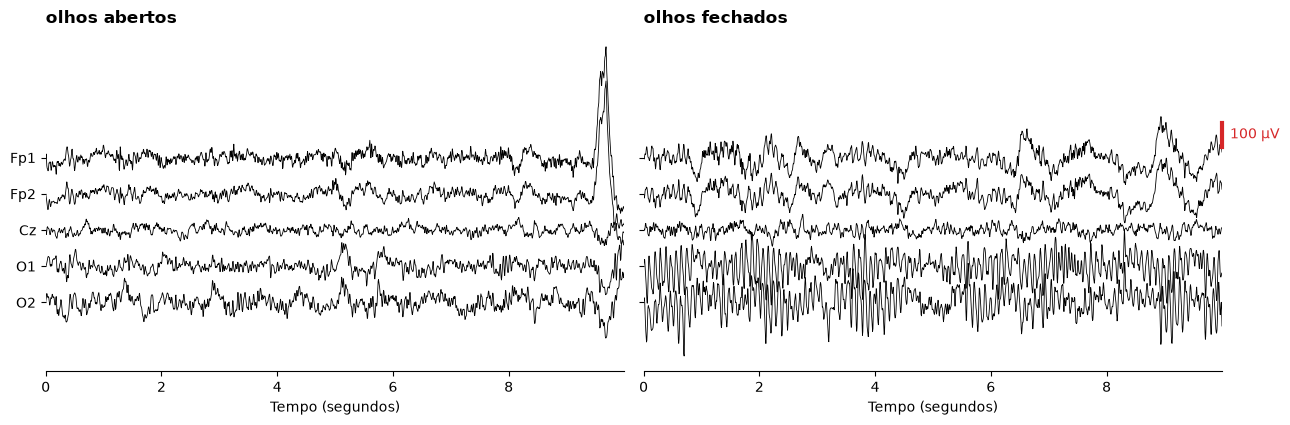

In [89]:
#@markdown Elétrodos a mostrar (separados por vírgulas) e trecho (segundos)
canais = "Fp1, Fp2, Cz, O1, O2"  #@param {type:"string"}
inicio_s = 0  #@param {type:"slider", min:0, max:50, step:5}

plot_traces_open_closed(olhos_abertos, olhos_fechados, channel_list(canais), start=inicio_s, duration=10)

- Com **olhos fechados**, os elétrodos occipitais (O1, O2) mostram uma oscilação regular de ~10 por segundo: o **ritmo alfa**. Conte as ondas em 1 segundo para estimar a frequência.
- Com **olhos abertos**, os frontopolares (Fp1, Fp2) mostram ondas lentas e amplas, simétricas e isoladas: **pestanejos**. São um **artefacto** — o globo ocular comporta-se como uma pequena pilha elétrica e o seu movimento é captado sobretudo pelos elétrodos mais próximos dos olhos. Na análise espectral, estas ondas lentas somam-se à banda **delta**.

<details><summary>Lista dos 64 elétrodos disponíveis</summary>

Fp1, Fpz, Fp2, AF7, AF3, AFz, AF4, AF8, F7, F5, F3, F1, Fz, F2, F4, F6, F8, FT7, FC5, FC3, FC1, FCz, FC2, FC4, FC6, FT8, T9, T7, C5, C3, C1, Cz, C2, C4, C6, T8, T10, TP7, CP5, CP3, CP1, CPz, CP2, CP4, CP6, TP8, P7, P5, P3, P1, Pz, P2, P4, P6, P8, PO7, PO3, POz, PO4, PO8, O1, Oz, O2, Iz

</details>

🔧 **Experimente:** mude `inicio_s` para percorrer o minuto de registo, ou acrescente elétrodos temporais (`T7, T8`) a `canais`.

### O efeito do filtro

O espectro do registo de olhos abertos **antes e depois** do filtro 1-40 Hz, até aos 80 Hz (metade da frequência de amostragem):

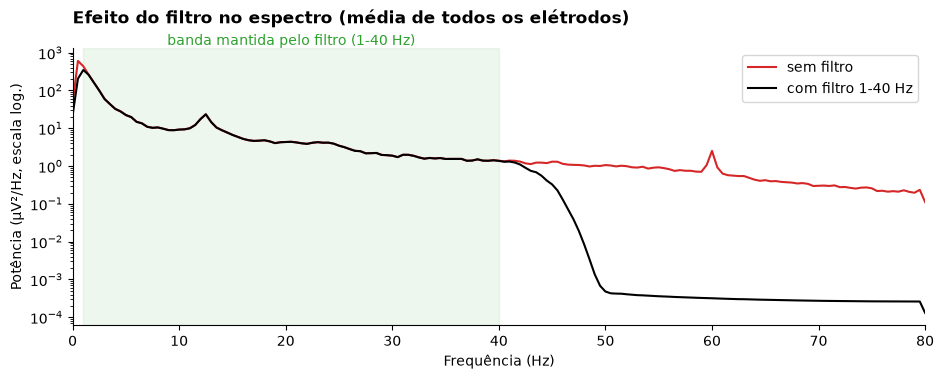

In [90]:
plot_filter_effect(olhos_abertos_sem_filtro, olhos_abertos)

- **Abaixo de 1 Hz**, o filtro atenua as derivas lentas, que não interessam à análise e "contaminariam" a banda delta. Neste registo são discretas; em registos longos ou com o doente a transpirar podem dominar o espectro.
- **Aos 60 Hz** surge um pico estreito: a **interferência da rede elétrica** (estes registos foram feitos nos EUA, onde a rede é a 60 Hz; na Europa seria a 50 Hz).
- **Entre 1 e 40 Hz** as duas curvas sobrepõem-se: o filtro não altera as bandas clássicas.

🔧 **Experimente:** no controlo `PARTICIPANTE` (início da secção), escolha o participante **5** e execute de novo os blocos. A interferência a 60 Hz é centenas de vezes maior — um elétrodo com mau contacto, ou um equipamento ligado perto, têm este efeito. O filtro resolve-a; sem ele, a "potência beta e gama" deste participante seria quase só rede elétrica.

### Segmentação em épocas e rejeição de épocas más

O filtro trata os artefactos **fora** das bandas de interesse, mas não os pestanejos, que caem na banda delta. Há técnicas que removem os artefactos do sinal preservando a atividade cerebral subjacente (por exemplo, a análise de componentes independentes, ICA). A abordagem mais simples — e a usada aqui — é **excluir os trechos contaminados** do cálculo do espectro.

Para isso, o registo é dividido em **épocas** (segmentos) de duração fixa — as mesmas janelas do método de Welch (secção 4). A figura mostra essa segmentação nos primeiros 20 segundos do registo: cada barra numerada é uma época de 2 s; com 50% de sobreposição, começa uma nova época a cada segundo e as barras alternam entre duas linhas.

Uma época é marcada como **má** (a vermelho) quando, em algum elétrodo, a amplitude pico-a-pico ultrapassa **`limiar` vezes o valor típico** (mediana) desse elétrodo no registo. Um limiar fixo em µV (por exemplo, 150 µV) é mais comum, mas depende muito do registo: com olhos fechados, o alfa occipital do participante 1 chega a ~300 µV pico-a-pico e um limiar fixo rejeitaria todas as épocas.

São apresentados **Fp1** (onde os pestanejos são máximos) e **Oz** (um dos elétrodos usados no espectro).

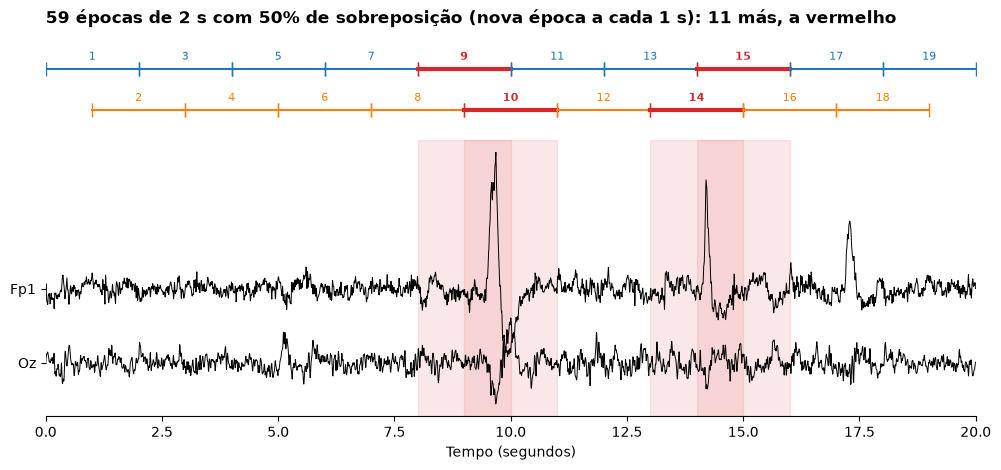

Épocas más (número: elétrodo com maior amplitude): 9: Fp2, 10: Fp2, 14: Fp1, 15: Fp1, 25: Fp1, 37: AF3, 38: AF3, 39: Fp1, 40: Fp2, 41: Fp2, 56: Fp1
Épocas boas: 48  (forma dos dados: (48, 64, 320) = épocas × elétrodos × amostras)


In [93]:
#@markdown Limiar: múltiplo da amplitude típica de cada elétrodo acima do qual a época é rejeitada
limiar = 3.0  #@param {type:"slider", min:1.5, max:5, step:0.5}
registo = "olhos abertos"  #@param ["olhos abertos", "olhos fechados"]

gravacao = {"olhos abertos": olhos_abertos, "olhos fechados": olhos_fechados}[registo]
epocas_boas = plot_epochs_segmentation(gravacao, threshold=limiar)
print(f"Épocas boas: {len(epocas_boas)}  (forma dos dados: {epocas_boas.get_data().shape} = épocas × elétrodos × amostras)")

Com o participante 1 e olhos abertos, as épocas más correspondem a **pestanejos**, detetados nos elétrodos frontopolares. Note-se que:

- com 50% de sobreposição, **um único pestanejo invalida duas épocas consecutivas** (por exemplo, 9 e 10);
- em **Oz** o pestanejo é quase invisível, mas a época é rejeitada por inteiro (todos os elétrodos), porque o critério considera o pior elétrodo;
- o pestanejo dos ~17 s **não é marcado** com `limiar = 3`: experimente 2,5. Limiares baixos rejeitam mais artefactos, mas também mais sinal cerebral.

🔧 **Experimente:** escolha `registo = "olhos fechados"`. Quantas épocas são rejeitadas? Porquê?

<details><summary>Resposta</summary>

Com os olhos fechados não há pestanejos, por isso (no participante 1) nenhuma época é rejeitada. O alfa occipital é amplo, mas é amplo **em todo o registo**: como o critério compara cada época com o valor típico do próprio elétrodo, não é confundido com um artefacto.

</details>

### Porque rejeitar? O efeito no espectro

O espectro dos elétrodos frontopolares calculado com **todas** as épocas e apenas com as épocas **boas** (as do bloco anterior):

In [ ]:
#@markdown Elétrodos onde comparar o espectro (separados por vírgulas)
canais_rejeicao = "Fp1, Fp2"  #@param {type:"string"}

plot_rejection_effect(gravacao, epocas_boas, picks=channel_list(canais_rejeicao))

Os pestanejos acrescentam potência sobretudo nas **frequências lentas (delta)**: com o participante 1, a potência delta frontal com todas as épocas é cerca de **4 vezes** maior. Sem rejeição, uma pessoa que pestaneja muito pareceria ter "mais delta" — um achado que, num EEG clínico, poderia sugerir disfunção cerebral.

🔧 **Experimente:** troque `canais_rejeicao` para `O1, O2`. A diferença é muito menor, porque os pestanejos quase não chegam aos elétrodos occipitais. Experimente também o participante **2**, que pestaneja muito mais.

⚠️ **Atenção:** a rejeição só funciona se o artefacto for **ocasional**. Se estiver presente em todo o registo (por exemplo, tensão muscular contínua), não há épocas "limpas" para comparar e o critério relativo não o deteta (ver secção 10).

### Espectro: olhos abertos vs. olhos fechados

> ❓ **Pergunta (antes de executar):** ao fechar os olhos, em que frequências espera ver a maior diferença? Em que elétrodos?

In [ ]:
#@markdown Região do escalpe cujos elétrodos são incluídos no espectro (média)
regiao = "posterior"  #@param ["posterior", "frontal", "central", "temporal"]

plot_open_closed(olhos_abertos, olhos_fechados, picks=REGIOES[regiao])

Com os olhos fechados surge um **pico bem definido na banda alfa** (8-13 Hz), ausente ou muito menor com os olhos abertos. Nas restantes bandas, as diferenças são pequenas.

🔧 **Experimente:** mude `regiao` para `frontal`. O pico alfa dos olhos fechados é muito menor: o ritmo alfa é **posterior**. Note também o excesso de delta com olhos abertos — os pestanejos, que aqui não foram rejeitados.

Note-se a **escala logarítmica** do eixo vertical: sem ela, as frequências lentas dominariam o gráfico. A figura seguinte mostra os mesmos dados numa escala linear:

In [ ]:
plot_open_closed(olhos_abertos, olhos_fechados, picks=REGIOES[regiao], log=False)

## 6. Medidas espectrais

A partir do espectro calculam-se as medidas numéricas que os programas de qEEG apresentam como tendências:

| Medida | Definição | Utilização clínica (exemplos) |
|---|---|---|
| **Potência absoluta** | área sob o espectro numa banda (µV²) | depende da amplitude do sinal, da impedância e da montagem |
| **Potência relativa** | potência da banda ÷ potência total (%) | menos sensível a diferenças de amplitude entre registos; ex.: variabilidade do alfa relativo (RAV) |
| **Razão alfa/delta (ADR)** | potência alfa ÷ potência delta | isquemia: uma diminuição sustentada pode sinalizar isquemia cerebral tardia após hemorragia subaracnoideia |
| **SEF95** | frequência abaixo da qual se encontra 95% da potência | monitorização da sedação/anestesia; lentificação |
| **Frequência do pico alfa** | frequência com maior potência entre 7 e 14 Hz | lentificação do ritmo dominante posterior (encefalopatia) |

In [ ]:
# Medidas calculadas nos elétrodos da região escolhida acima (controlo `regiao`)
medidas_abertos, medidas_fechados = print_measures(olhos_abertos, olhos_fechados, picks=REGIOES[regiao])
plot_relative_bars(medidas_abertos, medidas_fechados)

Ao fechar os olhos, a **potência alfa** (absoluta e relativa) e a **razão alfa/delta** aumentam claramente, e o **SEF95** desce ligeiramente, porque uma maior parte da potência passa a concentrar-se nos ~10 Hz.

A **frequência do pico alfa** com olhos fechados (~10 Hz) é a do ritmo dominante posterior. Com olhos abertos, o valor é **pouco fiável**: não existe um pico alfa definido (ver secção 5) e o cálculo devolve simplesmente o ponto mais alto entre 7 e 14 Hz. Um programa calcula sempre um número, mesmo quando o fenómeno que pretende medir não está presente.

🔧 **Experimente:** mude de participante (início da secção 5). Todos têm o mesmo aumento de alfa? A frequência do pico alfa é igual? Nem todas as pessoas têm um alfa reativo evidente — e isso, por si só, não é anormal.

⚠️ **Atenção aos limites das bandas.** A banda alfa é definida como 8-13 Hz no glossário da IFCN, mas há programas e autores que utilizam 8-12 Hz, ou bandas delta a começar em 0,5 Hz. Os valores numéricos **só são comparáveis** se as bandas, os elétrodos, a referência e a duração das janelas forem os mesmos.

## 7. Mapas topográficos

Calculando a potência alfa em **cada elétrodo**, é possível representar a sua distribuição no escalpe:

In [ ]:
#@markdown Banda de frequência representada nos mapas
banda = "alfa"  #@param ["delta", "teta", "alfa", "beta"]

plot_band_topomaps(olhos_abertos, olhos_fechados, band=banda)

O aumento da potência alfa com os olhos fechados é **máximo na região occipital**, como esperado para o ritmo dominante posterior. Os mapas topográficos permitem também avaliar **assimetrias** entre hemisférios (por exemplo, perda de alfa num hemisfério após um AVC), que nos programas de qEEG surgem como índices ou espectrogramas de assimetria.

🔧 **Experimente:** mude `banda` para `delta`. Com olhos abertos, onde está o máximo? (Pista: lembre-se dos pestanejos.)

## 8. O espectrograma: a FFT ao longo do tempo

Até aqui, cada espectro resumia um minuto inteiro de registo. O **espectrograma** (também designado CDSA, *color density spectral array*) repete a FFT em **janelas sucessivas** e apresenta o resultado como uma imagem:

- **eixo horizontal:** tempo;
- **eixo vertical:** frequência;
- **cor:** potência (em dB) — cores quentes para potência elevada, cores frias para potência baixa.

Cada coluna do espectrograma é **um espectro**, como os da secção 5, visto "de cima". Juntam-se os dois minutos de registo — **primeiro olhos abertos, depois olhos fechados**:

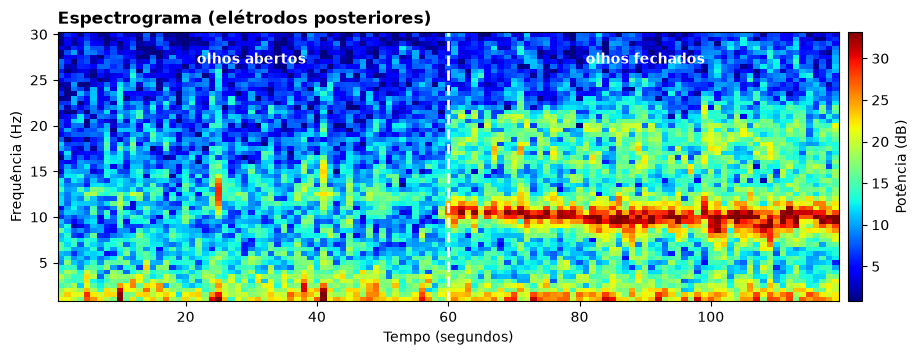

In [76]:
registo_completo = concatenate_runs(olhos_abertos, olhos_fechados)
mudanca = olhos_abertos.times[-1]          # instante em que o participante fecha os olhos

plot_spectrogram(registo_completo, "Espectrograma (elétrodos posteriores)", window=2.0, switch=mudanca)

Na segunda metade surge uma **faixa horizontal de cor quente em torno dos 10 Hz**: o ritmo alfa dos olhos fechados. É o mesmo raciocínio que permite reconhecer, num espectrograma de várias horas, as "chamas" de uma crise, as "riscas" de um padrão de surto-supressão ou a lentificação progressiva de um doente.

### Efeito da duração da janela

A escolha da duração da janela (secção 3) altera o aspeto do espectrograma:

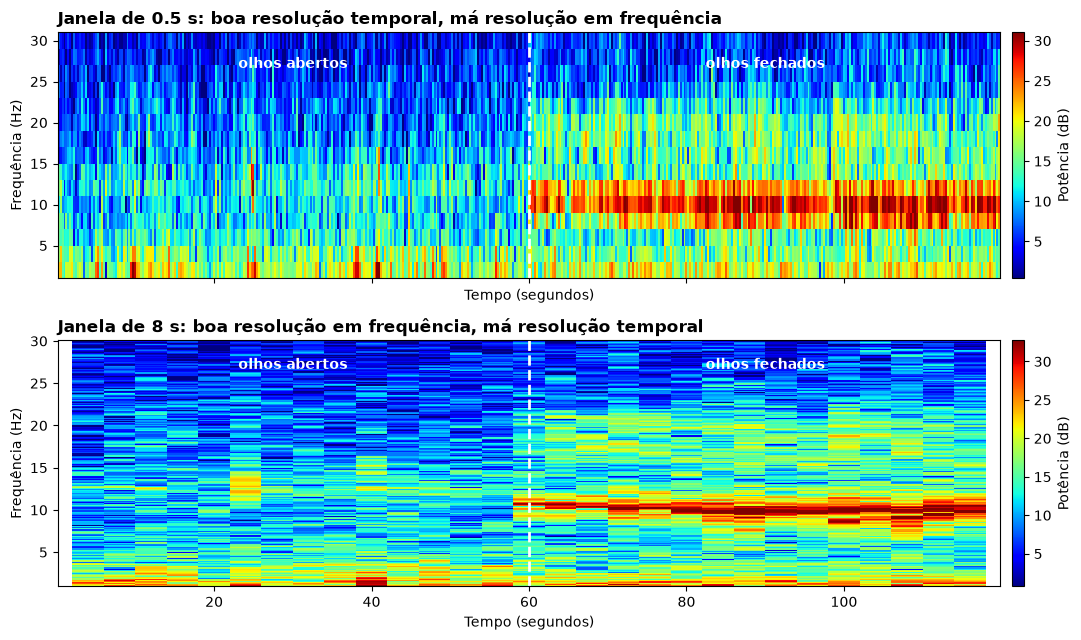

In [77]:
#@markdown Duração das janelas (segundos) dos dois espectrogramas a comparar
janela_curta = 0.5  #@param {type:"number"}
janela_longa = 8    #@param {type:"number"}

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
plot_spectrogram(registo_completo, f"Janela de {janela_curta:g} s: boa resolução temporal, má resolução em frequência",
                 window=janela_curta, ax=axes[0], switch=mudanca)
plot_spectrogram(registo_completo, f"Janela de {janela_longa:g} s: boa resolução em frequência, má resolução temporal",
                 window=janela_longa, ax=axes[1], switch=mudanca)
fig.tight_layout()
plt.show()

- Com **janelas curtas**, o espectrograma reage depressa a mudanças, mas as frequências ficam "esborratadas" na vertical e a imagem tem mais ruído.
- Com **janelas longas**, as frequências são nítidas, mas as transições ficam arrastadas no tempo e eventos breves podem passar despercebidos.

Os programas comerciais fazem esta escolha (e outras, como a suavização e a escala de cor) internamente. Conhecer o compromisso ajuda a interpretar o que se vê — e o que **não** se vê.

## 9. Tendências de qEEG

Os painéis de qEEG utilizados na monitorização contínua resumem cada janela num **único número** e apresentam a sua evolução ao longo do tempo (**tendência**). A partir do mesmo registo:

In [ ]:
#@markdown Duração de cada janela das tendências (segundos)
janela_tendencias = 2  #@param [1, 2, 4] {type:"raw"}

plot_trends(registo_completo, switch=mudanca, window=janela_tendencias)

| Tendência | Domínio | Resposta ao fechar os olhos |
|---|---|---|
| Amplitude pico-a-pico | tempo | aumenta (o alfa tem maior amplitude) |
| Potência alfa relativa | frequência | aumenta |
| Razão alfa/delta (ADR) | frequência | aumenta |
| SEF95 | frequência | desce ligeiramente: a potência concentra-se nos ~10 Hz; é uma medida mais útil para lentificações marcadas (sedação, encefalopatia) |

As tendências baseadas na **amplitude** (como o aEEG, o envelope de amplitude e a percentagem de supressão) calculam-se no **domínio do tempo**, sem FFT; as restantes derivam do **espectro** de cada janela.

⚠️ **Limitação essencial:** cada valor de uma tendência resume vários segundos de sinal num único número. Um artefacto (movimento, músculo, mau contacto) altera a tendência exatamente como um evento cerebral. **As tendências orientam a revisão; a confirmação faz-se sempre no EEG não processado.**

## 10. Registos diferentes: as mesmas medidas em EEG diferentes

Esta secção aplica as mesmas etapas a vários registos e compara as medidas obtidas. Serve para responder a duas perguntas: **como se comportam as medidas em EEG diferentes?** e **quando é que enganam?**

**Duas formas de usar esta secção:**
- **Com registos de exemplo (sem preparação):** no Colab, prima **Cancel** na janela de seleção de ficheiros (localmente, deixe a pasta `data/raw/registos_proprios/` vazia). São usados os dois minutos do participante da secção 5 e duas versões **simuladas** do registo de olhos abertos: uma com a amplitude reduzida a 1/4 (`hipovoltado_simulado`) e outra com atividade rápida contínua acrescentada nos elétrodos temporais e frontais, como na tensão muscular (`muscular_simulado`). Os quatro usam 19 elétrodos do sistema 10-20, como um EEG clínico.
- **Com registos próprios:** por exemplo, um EEG normal, um EEG hipovoltado, um EEG com artefacto muscular e um EEG com atividade epileptiforme.

**Antes de carregar ficheiros próprios:**
- Utilize apenas registos **anonimizados** e com autorização para fins de formação. O notebook apaga os dados pessoais do cabeçalho do ficheiro, mas o **nome do ficheiro** não é alterado: dê-lhe um nome descritivo (ex.: `normal.edf`, `hipovoltado.edf`). Esse nome é usado nas tabelas e figuras.
- No Colab, os ficheiros ficam apenas nesta sessão e são apagados quando ela termina. Localmente, coloque-os na pasta `data/raw/registos_proprios/` do projeto (não incluída no repositório).
- Formatos: EDF/BDF, FIF, BrainVision, EEGLAB, entre outros. O registo deve estar numa **montagem referencial** (todos os elétrodos contra a mesma referência), não bipolar. Os nomes clínicos dos canais (`EEG Fp1-REF`, `T3`, ...) são convertidos automaticamente; os canais que não são EEG (ECG, EOG, DC, ...) são postos de parte.
- Escolha, de preferência, trechos comparáveis: vigília em repouso, sem hiperventilação nem fotoestimulação. O trecho analisado define-se no bloco de parâmetros.

**Etapas aplicadas a cada registo:** filtro 1–40 Hz → referência média → segmentação em épocas de 2 s com 50% de sobreposição → rejeição das épocas más (mesmo critério da secção 5) → espectro de Welch (média de todos os elétrodos) → medidas.

In [ ]:
#@title Funções auxiliares (registos próprios)
# Funções utilizadas na secção 10. Não alteram os ficheiros originais.
import pandas as pd
if IN_COLAB:
    from google.colab import files

OWN_DIR = RAW_DIR / "registos_proprios"      # ficheiros carregados (fora do repositório)
OWN_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = ROOT / "data" / "processed"        # tabelas exportadas
OUT_DIR.mkdir(parents=True, exist_ok=True)
MAIN_EXTENSIONS = {".edf", ".bdf", ".fif", ".set", ".vhdr", ".cnt", ".gdf"}
# Sufixos de referência habituais em exportações clínicas (ex.: "EEG Fp1-REF", "C3-A1")
REFERENCE_SUFFIXES = {"ref", "le", "av", "avg", "ar", "a1", "a2", "a1a2", "m1", "m2", "linked"}
# Registos de exemplo: 19 elétrodos do sistema 10-20 e os elétrodos onde se simula o artefacto muscular
CLINICAL_1020 = ["Fp1", "Fp2", "F7", "F3", "Fz", "F4", "F8", "T7", "C3", "Cz", "C4", "T8",
                 "P7", "P3", "Pz", "P4", "P8", "O1", "O2"]
MUSCLE_CHANNELS = ["Fp1", "Fp2", "F7", "F8", "T7", "T8"]


def upload_own_recordings():
    # No Colab: abre a janela de seleção de ficheiros. Localmente: usa os ficheiros da pasta OWN_DIR.
    if IN_COLAB:
        for fname in files.upload():
            Path(fname).rename(OWN_DIR / fname)
    recordings = sorted(f for f in OWN_DIR.iterdir() if f.suffix.lower() in MAIN_EXTENSIONS)
    print("Registos disponíveis:", [f.name for f in recordings] or "nenhum: serão usados os registos de exemplo")
    return recordings


def example_recordings(open_rec, closed_rec, seed=0):
    # Registos usados quando não há ficheiros próprios: os dois minutos da secção 5 e duas versões
    # simuladas do registo de olhos abertos (amplitude reduzida a 1/4; atividade rápida acrescentada)
    base = open_rec.copy().pick(CLINICAL_1020)
    hypo = base.copy().apply_function(lambda x: x / 4)
    data = base.get_data()
    noise = np.random.default_rng(seed).normal(0, 1, (len(MUSCLE_CHANNELS), base.n_times))
    noise = mne.filter.filter_data(noise, base.info["sfreq"], 20, 40)   # atividade de 20-40 Hz
    noise *= 25e-6 / noise.std(axis=1, keepdims=True)                      # 25 µV eficazes (RMS)
    data[[base.ch_names.index(ch) for ch in MUSCLE_CHANNELS]] += noise
    muscle = mne.io.RawArray(data, base.info)
    return {"olhos_abertos": base, "olhos_fechados": closed_rec.copy().pick(CLINICAL_1020),
            "hipovoltado_simulado": hypo, "muscular_simulado": muscle}


def standard_name(ch, lookup):
    # "EEG FP1-REF" -> "Fp1"; devolve None se o canal não for um único elétrodo do escalpe
    key = ch.strip(" .").lower()
    for prefix in ("eeg ", "pol "):
        key = key.removeprefix(prefix)
    if "-" in key:
        key, reference = key.split("-", 1)
        if reference.strip() not in REFERENCE_SUFFIXES:
            return None
    return lookup.get(key.strip())


def load_own_recording(fname, start=0.0, duration=120.0):
    # Lê o registo, apaga os dados pessoais, normaliza os nomes dos elétrodos, põe de parte os canais
    # que não são EEG e aplica o mesmo pré-processamento das secções 5-9 ao trecho escolhido.
    # Exportações clínicas em EDF/BDF trazem muitas vezes anotações com acentos em Latin-1 (não UTF-8)
    kwargs = {"encoding": "latin1"} if Path(fname).suffix.lower() in {".edf", ".bdf"} else {}
    raw = mne.io.read_raw(fname, preload=True, **kwargs)
    raw.anonymize()                                       # apaga nome, data de nascimento e data do exame
    standard = mne.channels.make_standard_montage("standard_1005")
    lookup = {c.lower(): c for c in standard.ch_names}    # inclui a nomenclatura 10-20 antiga (T3, T5, ...)
    rename, others = {}, []
    for ch in raw.ch_names:
        new = standard_name(ch, lookup)
        if new and new not in raw.ch_names and new not in rename.values():
            rename[ch] = new
        elif not new:
            others.append(ch)
    raw.rename_channels(rename)
    raw.set_channel_types({ch: "misc" for ch in others})
    if len(mne.pick_types(raw.info, eeg=True)) < 3:
        raise ValueError(f"{Path(fname).name}: não foram reconhecidos elétrodos de EEG. "
                         "Confirme que o registo está numa montagem referencial (ex.: 'Fp1-REF').")
    raw.set_montage(standard, on_missing="ignore")
    stop = min(start + duration, raw.times[-1])
    raw.crop(tmin=start, tmax=stop)
    raw.filter(l_freq=1.0, h_freq=40.0, picks="eeg")
    raw.set_eeg_reference("average")
    return raw


def recording_measures(raw, threshold=3.0, window=2.0):
    # Épocas de `window` s (50% sobreposição) -> rejeição das épocas más (find_bad_epochs, secção 5)
    # -> espectro de Welch, média de todos os elétrodos -> medidas
    epochs = mne.make_fixed_length_epochs(raw, duration=window, overlap=window / 2, preload=True)
    bad = find_bad_epochs(epochs, threshold)
    good = epochs.copy().drop(list(bad))
    n = int(window * raw.info["sfreq"])
    sp = good.compute_psd(method="welch", fmin=1, fmax=40, picks="eeg", n_fft=n)
    f, p = sp.freqs, sp.get_data().mean(axis=(0, 1)) * 1e12   # µV²/Hz, média de épocas e elétrodos
    df = f[1] - f[0]
    band = lambda lo, hi: p[(f >= lo) & (f < hi)].sum() * df
    total = band(1, 30)
    cumulative = np.cumsum(p[(f >= 1) & (f < 30)]) / p[(f >= 1) & (f < 30)].sum()
    m = {"elétrodos": len(good.ch_names) - len(mne.pick_types(good.info, misc=True)),
         "épocas retidas": f"{len(good)}/{len(epochs)}",
         "amplitude (µV, RMS)": round(float(np.median(raw.get_data(picks="eeg").std(axis=1)) * 1e6), 1),
         "potência total (µV²)": round(float(total), 1)}
    for name, (lo, hi) in BANDS.items():
        m[f"{name} (%)"] = round(float(100 * band(lo, hi) / total))
    m["ADR (alfa/delta)"] = round(float(band(8, 13) / band(1, 4)), 2)
    m["SEF95 (Hz)"] = round(float(f[(f >= 1) & (f < 30)][np.searchsorted(cumulative, 0.95)]), 1)
    m["frequência dominante (Hz)"] = round(float(f[(f >= 1) & (f < 30)][np.argmax(p[(f >= 1) & (f < 30)])]), 1)
    return m, (f, p)


def quiz_labels(names, hide=True, seed=7):
    # Com hide=True, cada registo recebe uma letra (A, B, C...) por uma ordem baralhada, para o quiz
    if not hide:
        return {n: n for n in names}
    order = np.random.default_rng(seed).permutation(len(names))
    return {names[i]: "ABCDEFGHIJ"[k] for k, i in enumerate(order)}


def compare_recordings(recordings, labels, threshold=3.0):
    rows, spectra = {}, {}
    for name, raw in recordings.items():
        rows[labels[name]], spectra[labels[name]] = recording_measures(raw, threshold)
    table = pd.DataFrame(rows).T.sort_index()
    table.index.name = "registo"
    return table, dict(sorted(spectra.items()))


def plot_spectra_comparison(spectra):
    # Espectros sobrepostos (escala logarítmica), com as bandas clássicas assinaladas
    fig, ax = plt.subplots(figsize=(11, 4))
    for name, (lo, hi) in BANDS.items():
        ax.axvspan(lo, hi, color=BAND_COLORS[name], alpha=0.08)
        ax.text((lo + hi) / 2, 1.0, name, transform=ax.get_xaxis_transform(), ha="center", va="bottom",
                color=BAND_COLORS[name], fontsize=10)
    for label, (f, p) in spectra.items():
        ax.semilogy(f, p, lw=2, label=label)
    ax.set_xlim(1, 40)
    ax.set_xlabel("Frequência (Hz)")
    ax.set_ylabel("Potência (µV²/Hz, escala log.)")
    ax.set_title("Densidade espectral de potência (média de todos os elétrodos)", loc="left", fontweight="bold", pad=18)
    ax.legend(loc="upper right")
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()


def order_by_side(info, channels):
    # Ordena os elétrodos como num traçado clínico: hemisfério direito, linha média e hemisfério
    # esquerdo; em cada grupo, de anterior para posterior. Usa a posição de cada elétrodo no escalpe
    # (x > 0: direita; x < 0: esquerda; |x| < 5 mm: linha média).
    loc = {c["ch_name"]: c["loc"][:3] for c in info["chs"]}
    side = lambda x: 1 if abs(x) < 0.005 else (0 if x > 0 else 2)
    return sorted(channels, key=lambda ch: (side(loc[ch][0]), -loc[ch][1]))


def plot_traces_comparison(recordings, labels, start=10.0, duration=20.0, spacing=150, starts=None):
    # 20 s de cada registo, com todos os elétrodos de EEG (direita, linha média, esquerda) e a MESMA
    # escala vertical em todos (para comparar amplitudes). `starts` permite escolher um início
    # diferente para alguns registos (ex.: {"epi_gen": 30}); os restantes começam em `start`.
    items = sorted(recordings.items(), key=lambda kv: labels[kv[0]])
    n_max = max(len(mne.pick_types(raw.info, eeg=True)) for raw in recordings.values())
    fig, axes = plt.subplots(len(recordings), 1, figsize=(12, (0.3 * n_max + 1.2) * len(recordings)), squeeze=False)
    for ax, (name, raw) in zip(axes[:, 0], items):
        eeg = raw.copy().pick("eeg")
        picks = order_by_side(eeg.info, eeg.ch_names)
        t0 = min((starts or {}).get(name, start), raw.times[-1] - duration)
        data, times = raw.get_data(picks=picks, tmin=t0, tmax=t0 + duration, return_times=True)
        for i, trace in enumerate((data - data.mean(axis=1, keepdims=True)) * 1e6):
            ax.plot(times, trace - i * spacing, color="black", lw=0.6)
        ax.set_yticks(-np.arange(len(picks)) * spacing, picks)
        ax.set_ylim(-len(picks) * spacing, 1.5 * spacing)
        ax.set_xlim(times[0], times[-1])
        ax.plot([times[-1]] * 2, [spacing * 0.3, spacing * 0.3 + 100], color="tab:red", lw=3, clip_on=False)
        ax.text(times[-1], spacing * 0.3 + 50, "  100 µV", color="tab:red", va="center")
        ax.set_title(f"{labels[name]}" + ("" if labels[name] == name else f"  =  {name}"), loc="left", fontweight="bold")
        ax.spines[["top", "right", "left"]].set_visible(False)
    axes[-1, 0].set_xlabel("Tempo (segundos)")
    fig.tight_layout()
    plt.show()


def export_table(table, file_name="medidas_registos.csv"):
    path = OUT_DIR / file_name
    table.to_csv(path)
    if IN_COLAB:
        files.download(str(path))
    else:
        print(f"Tabela guardada em: {path}")

In [80]:
ficheiros = upload_own_recordings()

Registos disponíveis: ['Epi_temp_drt.edf', 'disf_cort_severa.edf', 'epi_gen.edf', 'muscle.edf']


### Medidas de cada registo

Com **`ESCONDER_NOMES` ativado**, os registos aparecem como A, B, C, D, por uma ordem baralhada: é a versão para o quiz. O trecho analisado é o mesmo para todos (início e duração, em segundos; nos registos de exemplo, que têm 1 minuto, usa-se o registo inteiro).

🔧 **Experimente:** desative `ESCONDER_NOMES` para ver os nomes verdadeiros.

In [ ]:
#@markdown Trecho analisado (segundos) e critério de rejeição das épocas (como na secção 5)
INICIO_S = 0  #@param {type:"number"}
DURACAO_S = 120  #@param {type:"number"}
LIMIAR_EPOCAS = 3.0  #@param {type:"slider", min:1.5, max:5, step:0.5}
ESCONDER_NOMES = True  #@param {type:"boolean"}

if ficheiros:
    registos = {f.stem: load_own_recording(f, INICIO_S, DURACAO_S) for f in ficheiros}
else:
    registos = example_recordings(olhos_abertos, olhos_fechados)
etiquetas = quiz_labels(list(registos), hide=ESCONDER_NOMES)
tabela, espectros = compare_recordings(registos, etiquetas, threshold=LIMIAR_EPOCAS)

plot_spectra_comparison(espectros)
tabela

> ❓ **Perguntas (antes de revelar):**
> 1. Qual dos registos é o **hipovoltado**? Que medida o denuncia?
> 2. Qual tem **artefacto muscular**? Sem ver o traçado, como seria interpretado?
> 3. Qual tem **atividade epileptiforme** (apenas com registos próprios)? Que forma tem o espectro?
>
> **Pontos de discussão:**
> - A **potência relativa** é uma proporção: num EEG hipovoltado pode parecer "normal", porque não depende da amplitude. A **potência absoluta** e a amplitude mostram a diferença.
> - O artefacto muscular aumenta a potência acima de 20 Hz e a **SEF95**: nas medidas, parece atividade rápida cerebral. A rejeição de épocas não o deteta, porque está presente em todo o registo (secção 5). Daí a importância de **ver o traçado** antes de interpretar as medidas.
> - Descargas periódicas produzem um **pico estreito** na frequência das descargas e os seus **harmónicos** (secção 1).

### Revelação: os traçados

Os mesmos 20 segundos de cada registo, com **todos os elétrodos** (hemisfério direito, linha média, hemisfério esquerdo) e **a mesma escala vertical**, para comparar amplitudes.

A  =  Epi_temp_drt
B  =  epi_gen
C  =  disf_cort_severa
D  =  muscle


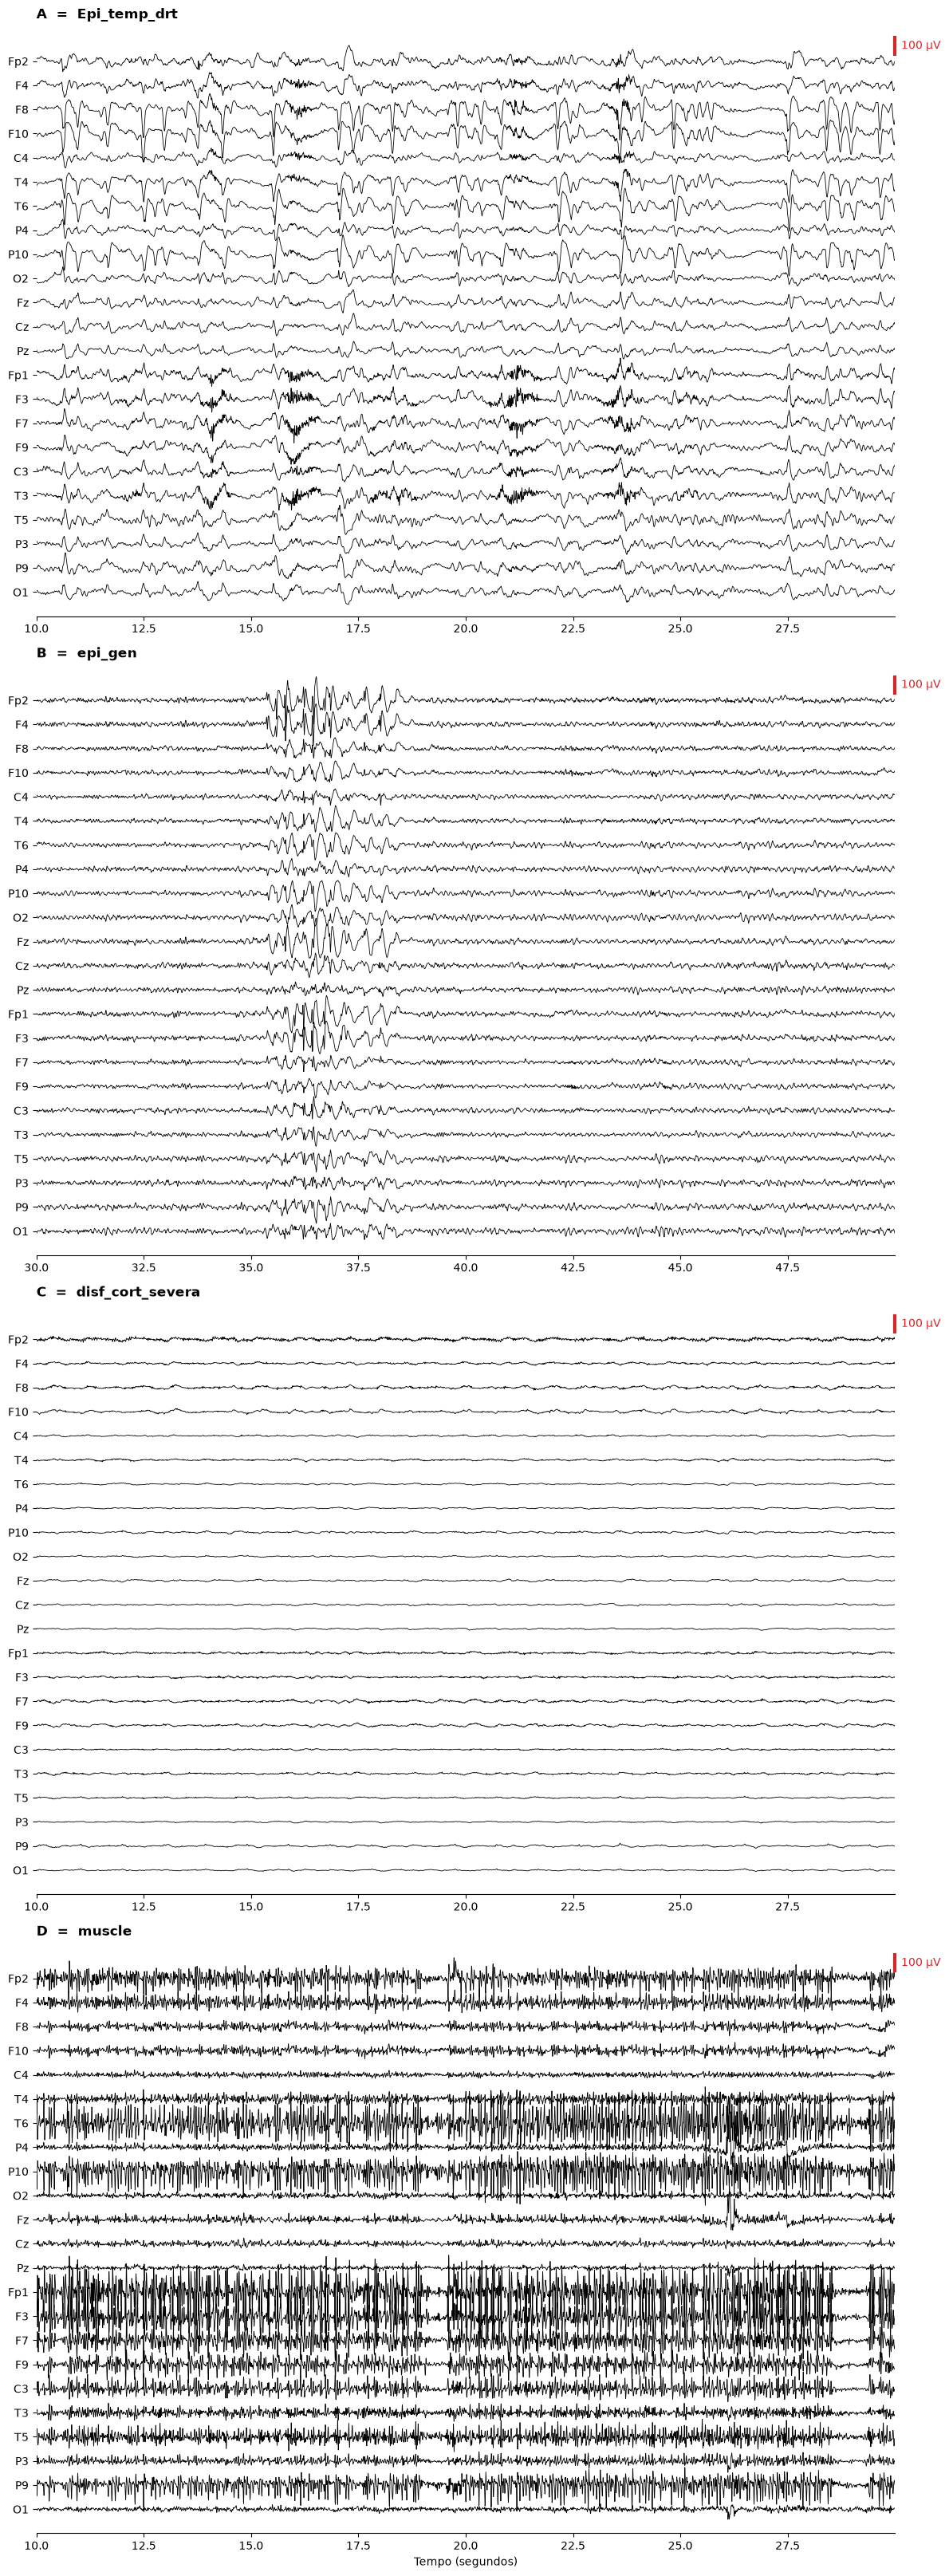

In [62]:
for nome, letra in sorted(etiquetas.items(), key=lambda kv: kv[1]):
    print(f"{letra}  =  {nome}")

plot_traces_comparison(registos, etiquetas, starts={"epi_gen": 30})

### Exportação da tabela

A tabela de medidas pode ser exportada em formato CSV (abre no Excel), para análise posterior. No Colab, o ficheiro é descarregado pelo navegador; localmente, fica na pasta `data/processed/` do projeto.

In [ ]:
export_table(tabela)

## Síntese

| Conceito | Ideia principal | Instrução |
|---|---|---|
| FFT | decompõe o sinal nas suas frequências | `np.fft.rfft(x)` |
| Filtro | remove derivas lentas (< 1 Hz), rede elétrica e parte do artefacto muscular | `raw.filter(l_freq=1.0, h_freq=40.0)` |
| Referência média | cada elétrodo menos a média de todos | `raw.set_eeg_reference("average")` |
| Potência | ≈ amplitude²; apresentada em escala logarítmica (dB) | `10 * np.log10(p)` |
| Resolução | Δf = 1 / duração da janela | — |
| Épocas | segmentos de duração fixa; as que têm artefactos são rejeitadas (pestanejos inflacionam o delta) | `mne.make_fixed_length_epochs(raw, duration=2.0)` |
| Welch | média de espectros de segmentos sobrepostos | `raw.compute_psd(method="welch")` |
| Medidas | potência absoluta/relativa, ADR, SEF95, pico alfa | `band_measures(raw)` |
| Espectrograma | FFT em janelas sucessivas | `scipy.signal.spectrogram(...)` |

## Exercícios

1. Na secção 5, percorra vários participantes com o controlo `PARTICIPANTE` (por exemplo, 2, 5, 6, 10) e execute de novo as secções 5 a 9. Todos apresentam o mesmo aumento de alfa? A frequência do pico alfa é igual? Algum tem mais artefactos?
2. Na secção 1, construa um sinal só com beta (`delta_uV = 0`, `alfa_uV = 0`, `beta_uV = 30`). Como se compara com o artefacto muscular simulado da secção 10?
3. Na secção 8, experimente janelas de `1` e `4` segundos. Qual escolheria para detetar uma crise de 10 segundos?
4. Na secção 5, compare as regiões (`regiao`) `posterior`, `central` e `frontal`. Em qual é maior a razão alfa/delta com olhos fechados (secção 6)?
5. Na secção 5, coloque `limiar = 1.5`. Quantas épocas sobram? Que efeito tem no espectro dos elétrodos occipitais?

### Leitura recomendada
- Ng MC, Jing J, Westover MB. *A Primer on EEG Spectrograms.* J Clin Neurophysiol. 2022;39(3):177-183. [Texto integral gratuito (PMC)](https://pmc.ncbi.nlm.nih.gov/articles/PMC8901534)
- Kane N, et al. *A revised glossary of terms most commonly used by clinical electroencephalographers.* Clin Neurophysiol Pract. 2017;2:170-185.